# 12-6. X3_l1 (X3) SV 모델 비교 ((d, D) 4가지)

SV 모델에서 (d, D) = (0,0), (0,1), (1,0), (1,1)를 CRPS, MSE, 커버리지로 비교한다.

- **조합**: (d, D) 4 x 스케일(원, 로그) 2 x 구간(자체, 리샘플링) 2 = 16개
- **구현**: `12-3`의 일반화 구현. 절편은 `d + D == 0`일 때만, (p, P)는 AR단독 auto_arima(`seasonal=True, m=4, max_Q=0`, AICc)가 선택, 적합 실패 시 AR단독으로 대체
- **평가**: 채점 origin 22개(origin 35 (~2019Q3) ~ 56 (~2024Q4)), CRPS는 `crps_ensemble`, 리샘플링은 `o' + h <= o`인 오차만 사용(11시리즈와 같은 방식)
- **단위 상수**: 모델에 넣는 값은 origin마다 그 시점까지의 훈련 구간 표준편차로 `100 / 표준편차`를 곱해 맞춘다(미래 정보 없음)
- **선정 규칙**: CRPS 1등의 ±10% 이내 중 커버리지가 90%에 가장 가까운 것

## 1. 구현 (AR단독 구조 선택 + SV)

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')
from dataclasses import dataclass
import numpy as np
import pandas as pd
import pmdarima as pm
import properscoring as ps
from scipy import stats
from arch.univariate import ARX, ConstantMean, GARCH, ZeroMean

from scipy.optimize import minimize
XI_MEAN, XI_VAR, MAX_PHI = -1.2704, np.pi ** 2 / 2, 0.97
H, ALPHA, P_MAX = 4, 0.10, 3
Z = stats.norm.ppf(1 - ALPHA / 2)


@dataclass(frozen=True)
class Spec:
    d: int = 1
    D: int = 0
    m: int = 4
    seasonal_ar: bool = False        # True면 계절 AR 차수 P도 AR단독 auto_arima가 탐색(D > 0이면 항상 탐색)

    @property
    def const(self):
        return self.d + self.D == 0


# ---------------------------------------------------------------- 차분·역차분·σ 전파
def diff_poly(sp):
    c = np.array([1.0])
    for _ in range(sp.d):
        c = np.convolve(c, [1.0, -1.0])
    for _ in range(sp.D):
        c = np.convolve(c, np.r_[1.0, np.zeros(sp.m - 1), -1.0])
    return c


def difference(y, sp):
    c, y = diff_poly(sp), np.asarray(y, float)
    k = len(c) - 1
    return y.copy() if k == 0 else np.convolve(y, c)[k:len(y)]


def undiff(w_fc, y, sp):
    c = diff_poly(sp)
    hist, out = list(map(float, y)), []
    for wf in w_fc:
        yt = wf - sum(c[i] * hist[-i] for i in range(1, len(c)))
        hist.append(yt)
        out.append(yt)
    return np.array(out)


def level_sigma(lags, ar, sp, innov_var):
    """h단계 수준 예측오차의 표준편차. 평균식 AR 다항식과 차분 다항식을 곱한 다항식으로 충격반응(psi)을 구한다."""
    ar_poly = np.zeros(max(lags) + 1 if len(lags) else 1)
    ar_poly[0] = 1.0
    for l, a in zip(lags, ar):
        ar_poly[l] -= a
    a_full = -np.convolve(ar_poly, diff_poly(sp))[1:]
    psi = np.zeros(H)
    for j in range(H):
        psi[j] = 1.0 if j == 0 else sum(a_full[k - 1] * psi[j - k] for k in range(1, min(j, len(a_full)) + 1))
    return np.sqrt(np.array([sum(psi[h - i] ** 2 * innov_var[i] for i in range(h + 1)) for h in range(H)]))


def lag_list(p, P, m):
    return sorted(set(range(1, p + 1)) | {m * j for j in range(1, P + 1)})


# ---------------------------------------------------------------- 구조 선택 (AR단독 auto_arima)
def select_structure(train, sp):
    kw = dict(d=sp.d, start_q=0, max_q=0, max_p=P_MAX, information_criterion="aicc", with_intercept=sp.const,
              suppress_warnings=True, error_action="ignore")
    if sp.D or sp.seasonal_ar:
        m = pm.auto_arima(train, seasonal=True, m=sp.m, D=sp.D, start_Q=0, max_Q=0, **kw)
        return m.order[0], m.seasonal_order[0], m
    m = pm.auto_arima(train, seasonal=False, **kw)
    return m.order[0], 0, m


def ar_forecast(m):
    fc, conf = m.predict(n_periods=H, return_conf_int=True, alpha=ALPHA)
    return np.asarray(fc), (conf[:, 1] - conf[:, 0]) / (2 * Z)


# ---------------------------------------------------------------- GARCH 동시
def garch_forecast(train, sp, lags):
    w = difference(train, sp)
    if lags:
        am = ARX(w, lags=lags, constant=sp.const, rescale=False)
    else:
        am = ConstantMean(w, rescale=False) if sp.const else ZeroMean(w, rescale=False)
    am.volatility = GARCH(p=1, q=1)
    res = am.fit(disp="off")
    f = res.forecast(horizon=H, reindex=False)
    ar = [res.params[f"y[{l}]"] for l in lags]
    fc = undiff(f.mean.values[-1], train, sp)
    sig = level_sigma(lags, ar, sp, f.residual_variance.values[-1])
    if not (np.all(np.isfinite(fc)) and np.all(np.isfinite(sig))):
        raise ValueError("non-finite forecast")
    return fc, sig


# ---------------------------------------------------------------- SV 동시 (QML + 칼만필터)
def is_ar_stable(lags, ar):
    if not len(lags):
        return True
    mx = max(lags)
    a = np.zeros(mx)
    for l, c in zip(lags, ar):
        a[l - 1] = c
    comp = np.zeros((mx, mx))
    comp[0, :] = a
    if mx > 1:
        comp[1:, :-1] = np.eye(mx - 1)
    return np.max(np.abs(np.linalg.eigvals(comp))) < 0.999


def sv_residuals(w, lags, ar, c):
    mx = max(lags) if len(lags) else 0
    return np.array([w[t] - c - sum(a * w[t - l] for a, l in zip(ar, lags)) for t in range(mx, len(w))])


def sv_qml_negloglik(z_centered, phi, sigma_eta2):
    P0 = sigma_eta2 / (1 - phi ** 2) if abs(phi) < 0.999 else sigma_eta2 * 100
    h_pred, P_pred, loglik = 0.0, P0, 0.0
    for z in z_centered:
        F = P_pred + XI_VAR
        v = z - h_pred
        loglik += -0.5 * (np.log(2 * np.pi * F) + v ** 2 / F)
        K = P_pred / F
        h_filt, P_filt = h_pred + K * v, P_pred * (1 - K)
        h_pred, P_pred = phi * h_filt, phi ** 2 * P_filt + sigma_eta2
    return -loglik


def _unpack(params, k, const):
    ar = params[:k]
    c = params[k] if const else 0.0
    j = k + (1 if const else 0)
    return ar, c, MAX_PHI * np.tanh(params[j]), np.exp(params[j + 1]) ** 2


def joint_sv_negloglik(params, w, lags, const):
    ar, c, phi, s2 = _unpack(params, len(lags), const)
    if not is_ar_stable(lags, ar):
        return 1e10
    z = np.log(sv_residuals(w, lags, ar, c) ** 2 + 1e-8)
    return sv_qml_negloglik(z - z.mean(), phi, s2)


def sv_forecast(train, sp, lags):
    w = difference(train, sp)
    k = len(lags)
    x0 = [0.0] * k + ([float(np.mean(w))] if sp.const else []) + [1.5, np.log(0.3)]
    res = minimize(joint_sv_negloglik, x0, args=(w, lags, sp.const), method="Nelder-Mead", options={"maxiter": 3000})
    ar, c, phi, s2 = _unpack(res.x, k, sp.const)
    if not is_ar_stable(lags, ar) or res.fun >= 1e9:
        raise ValueError("SV fit failed")
    z = np.log(sv_residuals(w, lags, ar, c) ** 2 + 1e-8)
    zm = z.mean()
    P, h = s2 / (1 - phi ** 2), 0.0
    for x in z - zm:
        K = P / (P + XI_VAR)
        hf, Pf = h + K * (x - h), P * (1 - K)
        h, P = phi * hf, phi ** 2 * Pf + s2
    past = list(w[-max(lags):]) if k else []
    mean_w = []
    for _ in range(H):
        pred = c + sum(a * past[-l] for a, l in zip(ar, lags))
        mean_w.append(pred)
        past.append(pred)
    v = [np.exp(zm - XI_MEAN + phi ** j * hf + (phi ** (2 * j) * Pf + s2 * sum(phi ** (2 * i) for i in range(j))) / 2) for j in range(1, H + 1)]
    fc, sig = undiff(mean_w, train, sp), level_sigma(lags, ar, sp, v)
    if not (np.all(np.isfinite(fc)) and np.all(np.isfinite(sig))):
        raise ValueError("non-finite forecast")
    return fc, sig


def sv_joint(train, sp):
    p, P, m = select_structure(train, sp)
    lags = lag_list(p, P, sp.m)
    try:
        fc, sig = sv_forecast(train, sp, lags)
        return fc, sig, (p, P), "SV"
    except Exception:
        nan = np.full(H, np.nan)
        return nan, nan, (p, P), "실패"


## 2. 계산

모든 origin(20~56)에서 적합해 오차 표본을 쌓고 채점 origin(35~56)만 평가한다. 로그는 `100 x log(y)`에서 적합해 원 스케일로 되돌려 채점한다. GARCH·SV는 표준화 오차로 리샘플링한다.

In [2]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
vals = raw[["quarter", "X3_l1"]].dropna()["X3_l1"].values.astype(float)
SCALE, N_ENS, INITIAL_CALIB = 100.0, 500, 15
SEED = 42                                               # 리샘플링 난수 시드(모든 변수, 모델, (d, D)가 같은 시드를 써서 같은 난수로 비교한다)
var_std = vals.std()
origins = list(range(20, len(vals) - H + 1))
U = stats.norm.ppf((np.arange(N_ENS) + 0.5) / N_ENS)
CASES = [(0, 0), (0, 1), (1, 0), (1, 1)]
CACHE = "../cache/cache_136_sv_dD_df.pkl"


def run(sp, logmode):
    rng = np.random.default_rng(SEED)
    tf = (lambda x: np.exp(np.asarray(x) / SCALE)) if logmode else (lambda x: x)
    errs = {h: [] for h in range(1, H + 1)}
    rows = []
    for oi, o in enumerate(origins):
        C = 100 / vals[:o].std()                                     # 단위 상수: 그 시점까지의 훈련 구간 표준편차로 정함(미래 정보 없음)
        series = SCALE * np.log(vals * C) if logmode else vals * C
        train, actual = series[:o], series[o:o + H]
        fc, sig, (p, P), src = sv_joint(train, sp)
        if oi >= INITIAL_CALIB:
            for h in range(1, H + 1):
                a, s_h = vals[o + h - 1], max(sig[h - 1], 1e-6)
                pool = np.array([e for o2, e in errs[h] if o2 + h <= o])
                samples = fc[h - 1] + s_h * rng.choice(pool - np.median(pool), size=N_ENS, replace=True)
                lo_r, hi_r = tf(np.quantile(samples, [ALPHA / 2, 1 - ALPHA / 2])) / C
                lo_n, hi_n = tf(fc[h - 1] - Z * s_h) / C, tf(fc[h - 1] + Z * s_h) / C
                med = float(tf(fc[h - 1])) / C
                base = {"d": sp.d, "D": sp.D, "스케일": "로그" if logmode else "원", "origin": o, "h": h, "p": p, "P": P, "모델": src,
                        "MSE": ((a - med) / var_std) ** 2, "pool_n": len(pool)}
                rows.append({**base, "구간": "리샘플링", "적중": float(lo_r <= a <= hi_r) * 100, "폭": (hi_r - lo_r) / var_std,
                             "crps": ps.crps_ensemble(a, tf(samples) / C) / var_std})
                rows.append({**base, "구간": "자체", "적중": float(lo_n <= a <= hi_n) * 100, "폭": (hi_n - lo_n) / var_std,
                             "crps": ps.crps_ensemble(a, tf(fc[h - 1] + s_h * U) / C) / var_std})
        for h in range(1, H + 1):
            if np.isfinite(fc[h - 1]):
                errs[h].append((o, (actual[h - 1] - fc[h - 1]) / max(sig[h - 1], 1e-6)))
    return pd.DataFrame(rows)


if os.path.exists(CACHE):
    res = pd.read_pickle(CACHE)
    print("캐시에서 로드:", len(res), "행")
else:
    res = pd.concat([run(Spec(d=d, D=D), lg) for d, D in CASES for lg in (False, True)], ignore_index=True)
    res.to_pickle(CACHE)
    print("계산 완료:", len(res), "행")

캐시에서 로드: 1408 행


## 3. 11-1 저장 결과와의 차이: (d, D) = (1, 0)

11시리즈는 `X3_l1`에 단위 상수를 곱하지 않았고 리샘플링 시드도 달랐다. 훈련 구간 단위 상수와 시드 42로 바뀐 영향을 본다.

In [3]:
c11 = pd.read_pickle("../cache/cache_107_rank_compare_df.pkl")
c11 = c11[c11["모델"] == "SV"].groupby(["스케일", "구간"])[["crps_ensemble", "MSE", "적중"]].mean()
mine = res[(res["d"] == 1) & (res["D"] == 0)].groupby(["스케일", "구간"])[["crps", "MSE", "적중"]].mean()
chk = pd.concat([mine.add_suffix("_new"), c11.rename(columns={"crps_ensemble": "crps"}).add_suffix("_old")], axis=1)
display(chk.round(6))
print(f"최대 차이: {np.abs(mine.values - c11[['crps_ensemble', 'MSE', '적중']].values).max():.20f}")

crps_new   MSE_new     적중_new  crps_old   MSE_old     적중_old
스케일 구간                                                                
로그  리샘플링  0.710061  1.053266  88.636364  0.714598  1.053266  87.500000
    자체    0.595049  1.053266  72.727273  0.595049  1.053266  72.727273
원   리샘플링  0.596451  1.052640  81.818182  0.598717  1.052640  82.954545
    자체    0.578270  1.052640  64.772727  0.578270  1.052640  64.772727

최대 차이: 1.13636363636364023932


최대 차이 0.00000000000000033은 반올림 수준이다. 두 구현이 σ를 구하는 방식이 달라서 마지막 자리에서 차이가 생긴다(기존은 충격반응을 누적합으로 쌓고, 새 구현은 AR 다항식과 차분 다항식을 곱해 구한다. 수학적으로는 같은 값이다). AR단독과 GARCH는 계산 경로가 거의 같아 차이가 정확히 0이었다.

## 4. 16개 조합의 CRPS, MSE, 커버리지

h 평균 -> origin 평균. 커버리지 목표는 90%다.

In [4]:
per = res.fillna({"crps": np.inf, "MSE": np.inf, "폭": np.inf}).groupby(["d", "D", "스케일", "구간", "origin"])[["crps", "MSE", "적중", "폭"]].mean(skipna=False)
tab = per.groupby(["d", "D", "스케일", "구간"]).mean(skipna=False).rename(columns={"crps": "CRPS", "적중": "커버리지(%)"})
with pd.option_context("display.float_format", lambda x: "inf" if np.isinf(x) else (f"{x:.1e}" if abs(x) >= 1e6 else f"{x:,.4f}")):
    display(tab)

CRPS    MSE  커버리지(%)       폭
d D 스케일 구간                                 
0 0 로그  리샘플링    inf 3.5946  57.9545     inf
        자체      inf 3.5946  73.8636     inf
    원   리샘플링 0.9999 2.5550  65.9091  4.9285
        자체   0.9931 2.5550  70.4545  3.9562
  1 로그  리샘플링 1.3577 1.7023 100.0000 34.2633
        자체   0.8854 1.7023  85.2273  8.9986
    원   리샘플링 0.8577 1.6842  93.1818  7.3647
        자체   0.7768 1.6842  75.0000  4.3393
1 0 로그  리샘플링 0.7101 1.0533  88.6364  7.9802
        자체   0.5950 1.0533  72.7273  3.0000
    원   리샘플링 0.5965 1.0526  81.8182  3.4407
        자체   0.5783 1.0526  64.7727  1.7953
  1 로그  리샘플링 1.5387 8.3958  82.9545 24.3966
        자체   1.2973 8.3958  61.3636  7.3884
    원   리샘플링 0.9461 2.5233  67.0455  4.2966
        자체   1.0017 2.5233  40.9091  2.2300

## 5. 모델 선정 규칙 적용

CRPS 1등의 ±10% 이내 중 커버리지가 90%에 가장 가까운 것을 고른다.

In [5]:
best = tab["CRPS"].min()
cand = tab[tab["CRPS"] <= best * 1.10].sort_values("CRPS").pipe(lambda x: x.iloc[np.argsort((x["커버리지(%)"] - 90).abs().values, kind="stable")])
print(f"CRPS 1등 {best:.4f}, 기준 {best * 1.10:.4f} 이내 {len(cand)}개 / 16")
display(cand.round(4))
print("선정:", cand.index[0], "(d, D, 스케일, 구간)")

CRPS 1등 0.5783, 기준 0.6361 이내 3개 / 16


CRPS     MSE  커버리지(%)       폭
d D 스케일 구간                                   
1 0 원   리샘플링  0.5965  1.0526  81.8182  3.4407
    로그  자체    0.5950  1.0533  72.7273  3.0000
    원   자체    0.5783  1.0526  64.7727  1.7953

선정: (np.int64(1), np.int64(0), '원', '리샘플링') (d, D, 스케일, 구간)


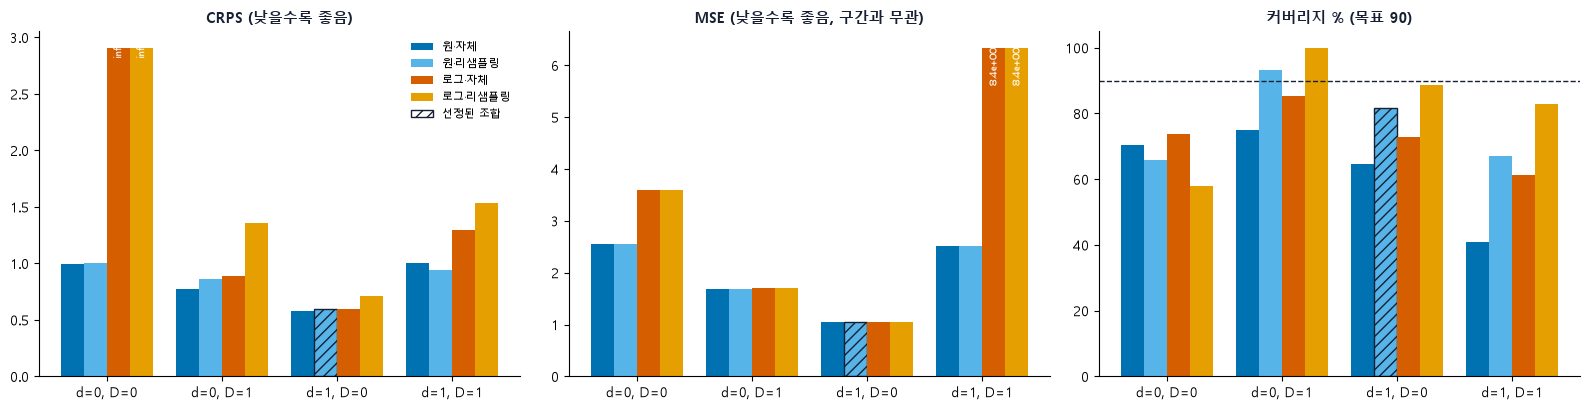

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
cols = {("원", "자체"): "#0072B2", ("원", "리샘플링"): "#56B4E9", ("로그", "자체"): "#D55E00", ("로그", "리샘플링"): "#E69F00"}
x = np.arange(len(CASES))
for ax, c, ttl in zip(axes, ["CRPS", "MSE", "커버리지(%)"], ["CRPS (낮을수록 좋음)", "MSE (낮을수록 좋음, 구간과 무관)", "커버리지 % (목표 90)"]):
    for j, ((sc, iv), col) in enumerate(cols.items()):
        v = [tab.loc[(d, D, sc, iv), c] for d, D in CASES]
        cap = 3 * tab[c].median()                                       # 값이 폭주한 막대는 상한에서 자르고 실제 값을 적는다
        bars = ax.bar(x + (j - 1.5) * 0.2, np.minimum(v, cap), 0.2, color=col, label=f"{sc}·{iv}")
        for b, val in zip(bars, v):
            if val > cap:
                ax.text(b.get_x() + b.get_width() / 2, cap, f"{val:.1e}", rotation=90, ha="center", va="top", fontsize=7, color="white")
        for (d, D), b in zip(CASES, bars):
            if (d, D, sc, iv) == tuple(cand.index[0]):                  # 5절에서 선정된 조합
                b.set_hatch("///")
                b.set_edgecolor("#172033")
    ax.set_xticks(x)
    ax.set_xticklabels([f"d={d}, D={D}" for d, D in CASES])
    ax.set_title(ttl, fontsize=10.5, fontweight="bold", color="#172033")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
axes[2].axhline(90, color="#172033", linestyle="--", linewidth=1)
from matplotlib.patches import Patch
h_, l_ = axes[0].get_legend_handles_labels()
axes[0].legend(h_ + [Patch(facecolor="white", edgecolor="#172033", hatch="///")], l_ + ["선정된 조합"], fontsize=8, frameon=False)
fig.tight_layout()
plt.show()

## 6. 선택된 구조 (p, P)

(d, D)별 AR단독이 고른 (p, P) 분포다.

In [7]:
st = res[(res["스케일"] == "원") & (res["구간"] == "자체") & (res["h"] == 1)]
display(st.groupby(["d", "D"]).apply(lambda g: pd.Series({"(p,P) 분포": dict(g.groupby(["p", "P"]).size()), "실패 횟수": int((g["모델"] == "실패").sum())})))

(p,P) 분포  실패 횟수
d D                                                      
0 0                        {(2, 0): 14, (3, 0): 8}      0
  1             {(2, 1): 6, (2, 2): 14, (3, 2): 2}      0
1 0                        {(1, 0): 18, (2, 0): 4}      0
  1  {(1, 1): 3, (1, 2): 14, (2, 1): 1, (2, 2): 4}      0

## 7. 세 모델 전체에서 선정

12-4~12-6의 48개 조합에 같은 규칙을 적용한다.

In [8]:
K5 = ["d", "D", "스케일", "구간"]
parts = []
for nm, f in [("AR단독", "cache_134_ar_dD_df.pkl"), ("GARCH", "cache_135_garch_dD_df.pkl"), ("SV", "cache_136_sv_dD_df.pkl")]:
    r_ = pd.read_pickle("../cache/" + f)
    t_ = r_.fillna({"crps": np.inf, "MSE": np.inf, "폭": np.inf}).groupby(K5 + ["origin"])[["crps", "MSE", "적중", "폭"]].mean(skipna=False).groupby(K5).mean(skipna=False).rename(columns={"crps": "CRPS", "적중": "커버리지(%)"})
    t_.insert(0, "모델", nm)
    parts.append(t_.reset_index())
allt = pd.concat(parts, ignore_index=True).set_index(["모델"] + K5)
b_ = allt["CRPS"].min()
c_ = allt[allt["CRPS"] <= b_ * 1.10].sort_values("CRPS").pipe(lambda x: x.iloc[np.argsort((x["커버리지(%)"] - 90).abs().values, kind="stable")])
print(f"CRPS 1등 {allt['CRPS'].idxmin()} {b_:.4f}, 기준 {b_ * 1.10:.4f} 이내 {len(c_)}개 / {len(allt)}")
print("모델별 후보 수:", c_.groupby(level=0).size().to_dict())
with pd.option_context("display.float_format", lambda x: "inf" if np.isinf(x) else (f"{x:.1e}" if abs(x) >= 1e6 else f"{x:,.4f}")):
    display(c_)
print("선정:", tuple(c_.index[0]), "(모델, d, D, 스케일, 구간)")

CRPS 1등 ('SV', np.int64(1), np.int64(0), '원', '자체') 0.5783, 기준 0.6361 이내 13개 / 48
모델별 후보 수: {'AR단독': 6, 'GARCH': 4, 'SV': 3}


CRPS    MSE  커버리지(%)      폭
모델    d D 스케일 구간                                
GARCH 1 0 원   리샘플링 0.6228 1.0674  84.0909 4.9758
SV    1 0 원   리샘플링 0.5965 1.0526  81.8182 3.4407
AR단독  0 0 로그  자체   0.6081 1.2150  77.2727 2.8856
GARCH 1 0 원   자체   0.5792 1.0674  76.1364 2.4595
AR단독  0 0 로그  리샘플링 0.6117 1.2150  75.0000 3.4077
SV    1 0 로그  자체   0.5950 1.0533  72.7273 3.0000
GARCH 0 0 로그  자체   0.6033 1.1909  72.7273 2.4202
AR단독  0 0 원   리샘플링 0.6137 1.2308  68.1818 1.9550
      1 0 원   자체   0.5930 1.1273  65.9091 1.7273
SV    1 0 원   자체   0.5783 1.0526  64.7727 1.7953
GARCH 0 0 원   자체   0.6230 1.1496  64.7727 1.8877
AR단독  1 0 원   리샘플링 0.5971 1.1273  62.5000 2.0644
      0 0 원   자체   0.6358 1.2308  55.6818 1.4948

선정: ('GARCH', np.int64(1), np.int64(0), '원', '리샘플링') (모델, d, D, 스케일, 구간)


## 결론

- **11-1과의 차이**: (d, D) = (1, 0)의 4개 조합이 11-1 저장 결과와 거의 같다(자체 구간은 차이 없음, 리샘플링은 CRPS 최대 차이 0.005, 적중은 88개 중 1개 예측 차이). 리샘플링 시드를 42로 통일한 영향이다.
- **d=0에서 SV는 불안정하다**: (0, 0)·로그에서 일부 origin의 구간 폭이 무한대로 발산해 CRPS가 무한대(inf)가 됐고, 원 스케일에서도 후반 origin의 폭이 12~15로 커진다.
- **D=1은 나빠진다**(d=1 기준 원·리샘플링 CRPS 0.60 -> 0.95). 다만 d=0일 때는 (0, 1)이 (0, 0)보다 낫다.
- **d=1, D=0**: CRPS 1등은 원·자체(0.5783)이고 MSE도 가장 낮다(1.053).
- **SV만 선정**: (1, 0)·원·리샘플링(CRPS 0.5965, 커버리지 81.8%).
- **세 모델 전체(7절)**: 48개 중 CRPS 1등(SV·(1, 0)·원·자체 0.5783)의 ±10% 이내가 13개(AR단독 6, GARCH 4, SV 3)이고 D=1은 없다. 커버리지가 90%에 가장 가까운 **GARCH·(1, 0)·원·리샘플링**(CRPS 0.6228, 커버리지 84.1%)이 선정되며, 11시리즈의 선정 모델(A)과 같다.


## 최종 정리

CRPS 1등과 선정 조합(CRPS 1등의 ±10% 이내 중 커버리지가 90%에 가장 가까운 것)이다.

In [9]:
def _lab(i):
    i = tuple(i)
    m = i[0] + "·" if isinstance(i[0], str) and i[0] in ("AR단독", "GARCH", "SV") else ""
    d, D, sc, iv = i[-4:]
    return f"{m}({int(d)},{int(D)})·{sc}·{iv}"


_fin = tab[np.isfinite(tab["CRPS"])]
_top, _sel = _fin["CRPS"].idxmin(), cand.index[0]
final = pd.DataFrame([_fin.loc[_top], _fin.loc[_sel]], index=["CRPS 1등", "선정"])[["CRPS", "MSE", "커버리지(%)", "폭"]]
final.insert(0, "조합", [_lab(_top), _lab(_sel)])
with pd.option_context("display.float_format", lambda x: "inf" if np.isinf(x) else (f"{x:.1e}" if abs(x) >= 1e6 else f"{x:,.4f}"), "display.width", 200):
    display(final)
print(f"CRPS 1등: {_lab(_top)} / 선정: {_lab(_sel)}" + (" (같은 조합)" if _top == _sel else ""))

,조합,CRPS,MSE,커버리지(%),폭
CRPS 1등,"(1,0)·원·자체",0.5783,1.0526,64.7727,1.7953
선정,"(1,0)·원·리샘플링",0.5965,1.0526,81.8182,3.4407


CRPS 1등: (1,0)·원·자체 / 선정: (1,0)·원·리샘플링


In [10]:
_t2, _s2 = c_.index[0], c_.index[0]
_top2 = allt["CRPS"].idxmin()
print("세 모델 전체(48개): CRPS 1등", _lab(_top2), "/ 선정", _lab(_s2), f"(CRPS {allt.loc[_s2, 'CRPS']:.4f}, 커버리지 {allt.loc[_s2, '커버리지(%)']:.1f}%)")

세 모델 전체(48개): CRPS 1등 SV·(1,0)·원·자체 / 선정 GARCH·(1,0)·원·리샘플링 (CRPS 0.6228, 커버리지 84.1%)
